In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Motor de Redes Neuronales
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(f"🔥 TensorFlow versión: {tf.__version__}")
print(f"🧠 Keras versión:      {keras.__version__}")

# 1. Rutas de los datos procesados en el Paso 2
processed_dir = "../data/processed"
train_path = os.path.join(processed_dir, "train.parquet")
val_path   = os.path.join(processed_dir, "val.parquet")
test_path  = os.path.join(processed_dir, "test.parquet")

print("\n📖 Cargando los 3 conjuntos de datos procesados...")
df_train = pd.read_parquet(train_path)
df_val   = pd.read_parquet(val_path)
df_test  = pd.read_parquet(test_path)

print(f"✅ Conjuntos cargados con éxito en memoria:")
print(f" • Entrenamiento (Train): {len(df_train):,} filas (Para ajustar los pesos)")
print(f" • Validación    (Val):    {len(df_val):,} filas (Para monitorear el sobreajuste)")
print(f" • Prueba        (Test):   {len(df_test):,} filas (El examen final)")

🔥 TensorFlow versión: 2.21.0
🧠 Keras versión:      3.15.1

📖 Cargando los 3 conjuntos de datos procesados...
✅ Conjuntos cargados con éxito en memoria:
 • Entrenamiento (Train): 263,225 filas (Para ajustar los pesos)
 • Validación    (Val):    57,099 filas (Para monitorear el sobreajuste)
 • Prueba        (Test):   56,362 filas (El examen final)


In [2]:
from sklearn.preprocessing import StandardScaler

# 1. Definir las columnas de entrada y la etiqueta
feature_cols = ['calle', 'bote', 'to_call', 'stack', 'pot_odds']
target_col = 'accion'

X_train_raw = df_train[feature_cols]
y_train = df_train[target_col].values

X_val_raw   = df_val[feature_cols]
y_val   = df_val[target_col].values

X_test_raw  = df_test[feature_cols]
y_test  = df_test[target_col].values

# 2. Escalador estándar (Media = 0, Desviación Estándar = 1)
scaler = StandardScaler()

# REGLA METODOLÓGICA: Solo ajustamos con Train
X_train = scaler.fit_transform(X_train_raw)

# Transformamos Val y Test con la misma escala aprendida
X_val  = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

print("=" * 65)
print("  ESCALADO DE VARIABLES COMPLETADO (Doc. Maestro § 8.2)")
print("=" * 65)
print(f" • Dimensión de X_train: {X_train.shape} (263k ejemplos x 5 variables)")
print(f" • Dimensión de X_val:   {X_val.shape}")
print(f" • Dimensión de X_test:  {X_test.shape}")

print("\n🔍 Demostración: Antes vs Después del escalado (Fila 0 de Train):")
print(" • Valores crudos en fichas:")
print("  ", dict(X_train_raw.iloc[0]))
print(" • Valores normalizados listos para las neuronas:")
print("  ", np.round(X_train[0], 3))

  ESCALADO DE VARIABLES COMPLETADO (Doc. Maestro § 8.2)
 • Dimensión de X_train: (263225, 5) (263k ejemplos x 5 variables)
 • Dimensión de X_val:   (57099, 5)
 • Dimensión de X_test:  (56362, 5)

🔍 Demostración: Antes vs Después del escalado (Fila 0 de Train):
 • Valores crudos en fichas:
   {'calle': np.float64(0.0), 'bote': np.float64(15.0), 'to_call': np.float64(10.0), 'stack': np.float64(3147.0), 'pot_odds': np.float64(0.4)}
 • Valores normalizados listos para las neuronas:
   [-0.616 -0.392 -0.194  0.874  0.874]


In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Fijar semilla para reproducibilidad
tf.random.set_seed(42)

# 1. Construcción del modelo secuencial
modelo = models.Sequential([
    # Entrada: 5 variables numéricas
    layers.Input(shape=(5,), name="Entrada_Variables"),
    
    # Capa 1: 128 neuronas
    layers.Dense(128, activation='relu', name="Capa_Densa_128"),
    layers.BatchNormalization(name="Normalizacion_1"),
    layers.Dropout(0.2, name="Dropout_20pct_1"),
    
    # Capa 2: 64 neuronas
    layers.Dense(64, activation='relu', name="Capa_Densa_64"),
    layers.Dropout(0.2, name="Dropout_20pct_2"),
    
    # Capa 3: 32 neuronas
    layers.Dense(32, activation='relu', name="Capa_Densa_32"),
    
    # Capa de salida: 3 neuronas con Softmax (probabilidades que suman 100%)
    layers.Dense(3, activation='softmax', name="Salida_Probabilidades")
], name="PHT_T_RedNeuronal_Poker")

# 2. Compilar el modelo con la función de pérdida y optimizador
modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Imprimir el resumen oficial de la red
print("=" * 65)
print("  ARQUITECTURA DE LA RED NEURONAL — Doc. Maestro § 3.3")
print("=" * 65)
modelo.summary()

  ARQUITECTURA DE LA RED NEURONAL — Doc. Maestro § 3.3


Model: "PHT_T_RedNeuronal_Poker"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Capa_Densa_128 (Dense)          │ (None, 128)            │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Normalizacion_1                 │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_20pct_1 (Dropout)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Capa_Densa_64 (Dense)           │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_20pct_2 (Dropout)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Capa_Densa_32 (Dense)           │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Salida_Probabilidades (Dense)   │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,715 (45.76 KB)

 Trainable params: 11,459 (44.76 KB)

 Non-trainable params: 256 (1.00 KB)

In [4]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 1. Configurar los guardianes contra el sobreajuste (Callbacks)
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-5,
    verbose=1
)

print("🚀 INICIANDO EL ENTRENAMIENTO DE LA RED NEURONAL...")
print(f" • Datos de Entrenamiento: {len(X_train):,} decisiones")
print(f" • Datos de Validación:    {len(X_val):,} decisiones")
print(" • Tamaño del lote (Batch): 512 decisiones por paso")
print(" • Épocas máximas:         25 (con parada automática si no mejora)\n")

# 2. Entrenar el modelo
history = modelo.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=512,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

print("\n✅ ¡ENTRENAMIENTO COMPLETADO CON ÉXITO!")

🚀 INICIANDO EL ENTRENAMIENTO DE LA RED NEURONAL...
 • Datos de Entrenamiento: 263,225 decisiones
 • Datos de Validación:    57,099 decisiones
 • Tamaño del lote (Batch): 512 decisiones por paso
 • Épocas máximas:         25 (con parada automática si no mejora)

Epoch 1/25


  1/515 ━━━━━━━━━━━━━━━━━━━━ 9:25 1s/step - accuracy: 0.2578 - loss: 1.3317

 22/515 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5313 - loss: 0.9931 

 42/515 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5744 - loss: 0.9322

 62/515 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5922 - loss: 0.9023

 83/515 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6008 - loss: 0.8843

... (753 outputs left out)

500/515 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6532 - loss: 0.7573

515/515 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6533 - loss: 0.7572 - val_accuracy: 0.6511 - val_loss: 0.7574 - learning_rate: 6.2500e-05


Restoring model weights from the end of the best epoch: 25.



✅ ¡ENTRENAMIENTO COMPLETADO CON ÉXITO!


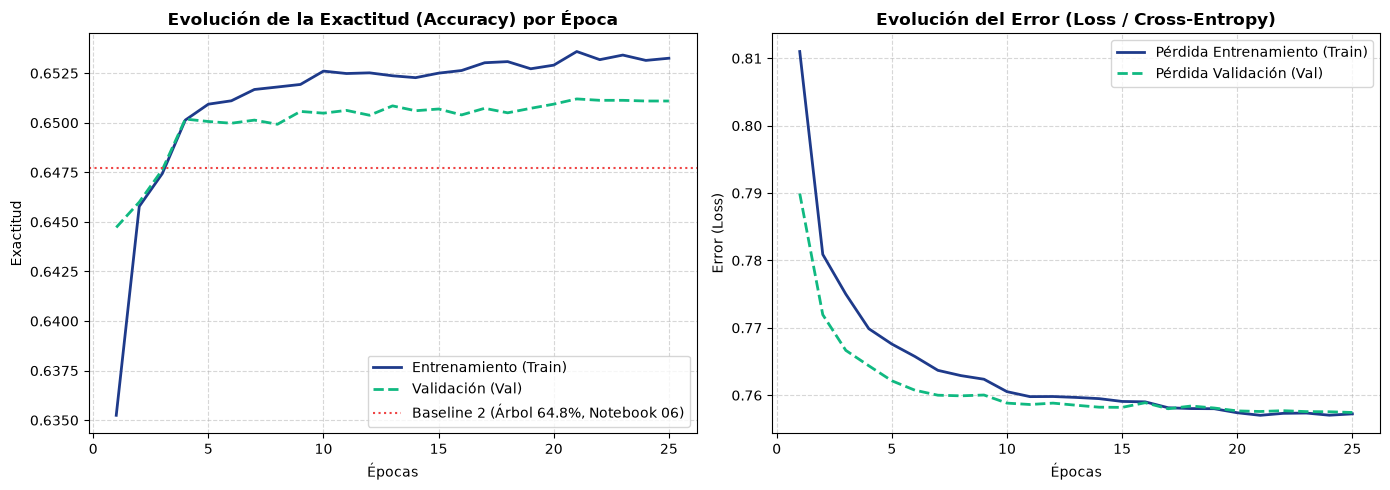

🎯 Exactitud final en Validación: 65.11%
📉 Pérdida final en Validación:   0.7574


In [5]:
# 1. Extraer el historial de métricas
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

# 2. Dibujar las curvas de aprendizaje
plt.figure(figsize=(14, 5))

# Gráfico 1: Exactitud (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Entrenamiento (Train)', color='#1e3a8a', linewidth=2)
plt.plot(epochs_range, val_acc, label='Validación (Val)', color='#10b981', linewidth=2, linestyle='--')
plt.axhline(y=0.6477, color='#ef4444', linestyle=':', label='Baseline 2 (Árbol 64.8%, Notebook 06)')
plt.title('Evolución de la Exactitud (Accuracy) por Época', fontsize=12, fontweight='bold')
plt.xlabel('Épocas')
plt.ylabel('Exactitud')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)

# Gráfico 2: Función de Pérdida (Loss)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Pérdida Entrenamiento (Train)', color='#1e3a8a', linewidth=2)
plt.plot(epochs_range, val_loss, label='Pérdida Validación (Val)', color='#10b981', linewidth=2, linestyle='--')
plt.title('Evolución del Error (Loss / Cross-Entropy)', fontsize=12, fontweight='bold')
plt.xlabel('Épocas')
plt.ylabel('Error (Loss)')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
os.makedirs('../informe/figuras', exist_ok=True)
plt.savefig('../informe/figuras/modelo2_curvas_aprendizaje.png', dpi=150, bbox_inches='tight')
plt.show()

print("=" * 65)
print(f"🎯 Exactitud final en Validación: {val_acc[-1] * 100:.2f}%")
print(f"📉 Pérdida final en Validación:   {val_loss[-1]:.4f}")
print("=" * 65)

🎓 APLICANDO EL EXAMEN FINAL EN TEST (56.362 decisiones inéditas)...

  1/111 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step

 58/111 ━━━━━━━━━━━━━━━━━━━━ 0s 879us/step

111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  

111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


  RESULTADOS OFICIALES EN EL CONJUNTO DE PRUEBA (TEST)
 • Exactitud en Test (Accuracy): 64.86%
 • Pérdida en Test (Loss):        0.7578

📋 REPORTE DE CLASIFICACIÓN DETALLADO:
                precision    recall  f1-score   support

      Fold (0)     0.6635    0.9598    0.7846     27111
Check/Call (1)     0.6175    0.5444    0.5787     15897
 Bet/Raise (2)     0.6013    0.1409    0.2283     13354

      accuracy                         0.6486     56362
     macro avg     0.6274    0.5484    0.5305     56362
  weighted avg     0.6358    0.6486    0.5947     56362



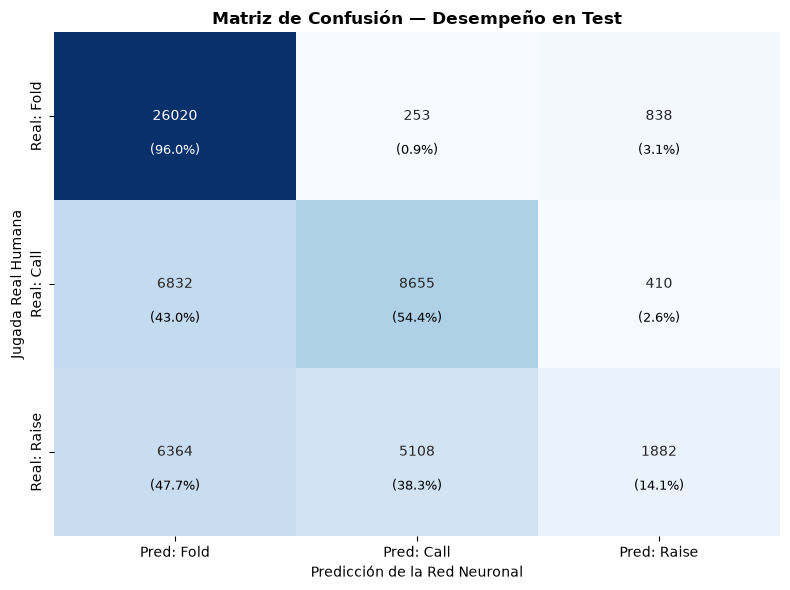


💾 Métricas guardadas en informe/metricas/modelo2.json


In [6]:
from sklearn.metrics import classification_report, confusion_matrix

print("🎓 APLICANDO EL EXAMEN FINAL EN TEST (56.362 decisiones inéditas)...\n")

# 1. Obtener las probabilidades que predice la red (Softmax)
y_pred_probs = modelo.predict(X_test, batch_size=512)

# La clase predicha es la que tiene mayor probabilidad (argmax)
y_pred = np.argmax(y_pred_probs, axis=1)

# 2. Evaluación oficial de Keras en Test
test_loss, test_acc = modelo.evaluate(X_test, y_test, verbose=0)

print("=" * 65)
print("  RESULTADOS OFICIALES EN EL CONJUNTO DE PRUEBA (TEST)")
print("=" * 65)
print(f" • Exactitud en Test (Accuracy): {test_acc * 100:.2f}%")
print(f" • Pérdida en Test (Loss):        {test_loss:.4f}")
print("=" * 65)

# 3. Reporte formal de métricas por clase
nombres_clases = ['Fold (0)', 'Check/Call (1)', 'Bet/Raise (2)']
print("\n📋 REPORTE DE CLASIFICACIÓN DETALLADO:")
print(classification_report(y_test, y_pred, target_names=nombres_clases, digits=4))

# 4. Graficar la Matriz de Confusión con mapa de calor
cm = confusion_matrix(y_test, y_pred)
cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=['Pred: Fold', 'Pred: Call', 'Pred: Raise'],
    yticklabels=['Real: Fold', 'Real: Call', 'Real: Raise'],
    cbar=False
)

# Agregar los porcentajes debajo de cada número
for i in range(3):
    for j in range(3):
        color_texto = 'white' if cm[i, j] > (len(y_test) / 6) else 'black'
        plt.text(j + 0.5, i + 0.7, f"({cm_pct[i, j]:.1f}%)", ha="center", va="center", color=color_texto, fontsize=9)

plt.title('Matriz de Confusión — Desempeño en Test', fontsize=12, fontweight='bold')
plt.ylabel('Jugada Real Humana')
plt.xlabel('Predicción de la Red Neuronal')
plt.tight_layout()
plt.savefig('../informe/figuras/modelo2_matriz_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

# 5. Guardar las métricas oficiales para el informe académico
import json
from sklearn.metrics import f1_score
os.makedirs('../informe/metricas', exist_ok=True)
metricas_m2 = {
    "modelo": "Modelo 2 - MLP 5 variables, fuga corregida",
    "test_accuracy": round(float(test_acc), 4),
    "test_loss": round(float(test_loss), 4),
    "f1_macro": round(float(f1_score(y_test, y_pred, average='macro')), 4),
    "reporte_por_clase": classification_report(y_test, y_pred, target_names=nombres_clases, output_dict=True),
    "matriz_confusion": cm.tolist(),
    "n_test": int(len(y_test))
}
with open('../informe/metricas/modelo2.json', 'w', encoding='utf-8') as f:
    json.dump(metricas_m2, f, ensure_ascii=False, indent=2)
print("\n💾 Métricas guardadas en informe/metricas/modelo2.json")

In [7]:
import joblib

# 1. Crear la carpeta oficial de modelos si no existe
models_dir = "../models/v2_corregido"
os.makedirs(models_dir, exist_ok=True)

model_file = os.path.join(models_dir, "pht_t_modelo_poker.keras")
scaler_file = os.path.join(models_dir, "scaler_poker.pkl")

# 2. Guardar la red neuronal y el escalador
print("💾 Guardando el modelo y el escalador en models/v2_corregido/...")
modelo.save(model_file)
joblib.dump(scaler, scaler_file)

print("\n✅ ¡ARTEFACTOS GUARDADOS CON ÉXITO!")
print(f" • Red Neuronal: {model_file} ➔ ({os.path.getsize(model_file) / 1024:.1f} KB)")
print(f" • Escalador:    {scaler_file} ➔ ({os.path.getsize(scaler_file) / 1024:.1f} KB)")

# 3. Comprobación de rigor: Cargar y probar una predicción rápida
print("\n🧪 PROBANDO CARGA DESDE DISCO (Smoke Test de Inferencia):")
modelo_cargado = keras.models.load_model(model_file)
scaler_cargado = joblib.load(scaler_file)

# Situación de prueba: Flop (calle 1), Bote de 100 fichas, apuesta de 50 a pagar, stack de 1200
situacion_prueba = pd.DataFrame([[1, 100.0, 50.0, 1200.0, 50.0 / 150.0]], columns=feature_cols)
situacion_escalada = scaler_cargado.transform(situacion_prueba)
probabilidades = modelo_cargado.predict(situacion_escalada, verbose=0)[0]

print("Escenario de prueba: Flop | Bote: 100 | Apuesta: 50 | Stack: 1200")
print(f"Predicción del modelo cargado:")
print(f" • Probabilidad de Fold:       {probabilidades[0] * 100:.2f}%")
print(f" • Probabilidad de Check/Call: {probabilidades[1] * 100:.2f}%")
print(f" • Probabilidad de Bet/Raise:  {probabilidades[2] * 100:.2f}%")
print("\n🎉 ¡Paso 4 Completado al 100%! El modelo está vivo y listo para predecir.")

💾 Guardando el modelo y el escalador en models/v2_corregido/...

✅ ¡ARTEFACTOS GUARDADOS CON ÉXITO!
 • Red Neuronal: ../models/v2_corregido\pht_t_modelo_poker.keras ➔ (175.5 KB)
 • Escalador:    ../models/v2_corregido\scaler_poker.pkl ➔ (1.0 KB)

🧪 PROBANDO CARGA DESDE DISCO (Smoke Test de Inferencia):


Escenario de prueba: Flop | Bote: 100 | Apuesta: 50 | Stack: 1200
Predicción del modelo cargado:
 • Probabilidad de Fold:       52.75%
 • Probabilidad de Check/Call: 35.72%
 • Probabilidad de Bet/Raise:  11.53%

🎉 ¡Paso 4 Completado al 100%! El modelo está vivo y listo para predecir.


### 🧠 Análisis Crítico del Modelo 2 (fuga corregida)

1. **De 92.90% a ~65%:** el Modelo 1 no había aprendido póker. En las jugadas de *Check/Call* y *Bet/Raise* el bote se registraba **después** de actuar y en los *Fold* **antes**; la red aprendió a detectar esa inconsistencia (fuga de información). Al guardar siempre la foto de la mesa *antes* de la acción, la exactitud cae a su valor real.
2. **Empate técnico con el árbol:** con las mismas 5 variables públicas, la red apenas supera al Baseline 2 (64.77%). La información disponible, no la arquitectura, es el límite.
3. **Bet/Raise casi invisible:** el *recall* de las agresiones es muy bajo. Sin cartas privadas ni contexto (posición, historial de apuestas), las subidas son difíciles de anticipar.
4. **Prueba de cordura:** en el escenario de prueba (Flop, bote 100, apuesta 50) el Modelo 1 respondía 100% *Fold*; el Modelo 2 reparte la probabilidad entre las tres acciones, como haría un humano.
5. **Siguiente paso:** el Modelo 3 añade ~45 variables públicas y el archivo completo de manos para medir dónde está el techo sin cartas.